In [2]:
%matplotlib inline 
# the line above is a command that configures Matplotlib to render plot images directly inside the Jupyter Notebook, beneath the code cell that generated them.
# we will need to have "scikit-learn" package installed in our local environment, after activating the environment (such as funtimes)
# example (Mac): 
#    conda activate funtimes
#    conda install scikit-learn -y
# more instructions if needed: https://scikit-learn.org/stable/install.html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

# Linear model and basic functions from scikit-learn
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Specific models we will use beyond linear regression from scikit-learn
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import RadiusNeighborsRegressor

In [3]:
#load data
#load in csv file 

#set path
infile = '/Users/summercollier/OEAS805/HW3/CBP_TWQM_MAIN_WQ_2021_2026_surface.csv'

data= pd.read_csv(infile, sep = ',' , low_memory= False)


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1223 entries, 0 to 1222
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Station                1223 non-null   object 
 1   FieldActivityId        1223 non-null   int64  
 2   Cruise                 1223 non-null   object 
 3   Program                1223 non-null   object 
 4   Project                1223 non-null   object 
 5   DataCollector          1223 non-null   object 
 6   DataProvider           1223 non-null   object 
 7   Latitude               1223 non-null   float64
 8   Longitude              1223 non-null   float64
 9   SampleDate             1223 non-null   object 
 10  SampleTime             1223 non-null   object 
 11  TotalDepthM            1223 non-null   float64
 12  UpperPycnoclineDepthM  1022 non-null   float64
 13  LowerPycnoclineDepthM  1022 non-null   float64
 14  SampleDepthM           1223 non-null   float64
 15  Laye

In [6]:
data.columns

Index(['Station', 'FieldActivityId', 'Cruise', 'Program', 'Project',
       'DataCollector', 'DataProvider', 'Latitude', 'Longitude', 'SampleDate',
       'SampleTime', 'TotalDepthM', 'UpperPycnoclineDepthM',
       'LowerPycnoclineDepthM', 'SampleDepthM', 'Layer', 'SampleType',
       'SampleReplicate', 'Parameter', 'Qualifier', 'MeasureValue',
       'MeasureUnit', 'Method', 'Lab', 'Problem', 'PrecisionPC', 'BiasPC',
       'Details', 'TierLevel'],
      dtype='object')

In [7]:
data.describe

<bound method NDFrame.describe of      Station  FieldActivityId  Cruise Program Project DataCollector  \
0     CB4.1C           785801  BAY900    TWQM    MAIN         MDDNR   
1     CB4.1C           785781  BAY898    TWQM    MAIN         MDDNR   
2     CB4.1C           785724  BAY895    TWQM    MAIN         MDDNR   
3     CB4.1C           785723  BAY894    TWQM    MAIN         MDDNR   
4     CB4.1C           785680  BAY893    TWQM    MAIN         MDDNR   
...      ...              ...     ...     ...     ...           ...   
1218  CB4.1C           699206  BAY814    TWQM    MAIN         MDDNR   
1219  CB4.1C           611589  BAY812    TWQM    MAIN         MDDNR   
1220  CB4.1C           608274  BAY806    TWQM    MAIN         MDDNR   
1221  CB4.1C           608260  BAY805    TWQM    MAIN         MDDNR   
1222  CB4.1C           608240  BAY802    TWQM    MAIN         MDDNR   

     DataProvider  Latitude  Longitude  SampleDate  ... Qualifier  \
0           MDDNR  38.82593  -76.39945  2025

In [8]:
data.describe()

,FieldActivityId,Latitude,Longitude,TotalDepthM,UpperPycnoclineDepthM,LowerPycnoclineDepthM,SampleDepthM,MeasureValue,PrecisionPC,BiasPC,Details
count,1223.000000,1.223000e+03,1.223000e+03,1223.000000,1022.000000,1022.000000,1223.000000,1223.000000,0.0,0.0,0.0
mean,683991.873262,3.882593e+01,-7.639945e+01,31.965168,6.754795,15.912916,0.482829,682.520790,NaN,NaN,NaN
std,60983.858976,4.691500e-13,1.634917e-12,0.864359,3.580874,3.726805,0.091090,3712.242591,NaN,NaN,NaN
min,608240.000000,3.882593e+01,-7.639945e+01,30.400000,0.700000,4.500000,0.000000,-0.001050,NaN,NaN,NaN
25%,625871.000000,3.882593e+01,-7.639945e+01,31.000000,3.500000,13.500000,0.500000,0.018400,NaN,NaN,NaN
50%,670930.000000,3.882593e+01,-7.639945e+01,32.000000,6.500000,16.500000,0.500000,0.447500,NaN,NaN,NaN
75%,699303.000000,3.882593e+01,-7.639945e+01,32.600000,9.500000,18.500000,0.500000,4.800000,NaN,NaN,NaN
max,785833.000000,3.882593e+01,-7.639945e+01,33.500000,14.500000,21.500000,0.500000,28200.000000,NaN,NaN,NaN


In [9]:
#unique variables
variables =data['Parameter'].unique()
print(variables)

['CHLA' 'DIN' 'DO' 'DON' 'DOP' 'KD' 'NH4F' 'NO23F' 'NO2F' 'NO3F' 'PC' 'PH'
 'PHEO' 'PN' 'PO4F' 'PP' 'SALINITY' 'SECCHI' 'SIGMA_T' 'SPCOND' 'TDN'
 'TDP' 'TN' 'TON' 'TP' 'TSS' 'WTEMP']


In [12]:
#listing all functions from scikit learn 
options = [item for item in dir(linear_model) if not item.startswith("_")]
print(options)

['ARDRegression', 'BayesianRidge', 'ElasticNet', 'ElasticNetCV', 'GammaRegressor', 'HuberRegressor', 'Lars', 'LarsCV', 'Lasso', 'LassoCV', 'LassoLars', 'LassoLarsCV', 'LassoLarsIC', 'LinearRegression', 'LogisticRegression', 'LogisticRegressionCV', 'MultiTaskElasticNet', 'MultiTaskElasticNetCV', 'MultiTaskLasso', 'MultiTaskLassoCV', 'OrthogonalMatchingPursuit', 'OrthogonalMatchingPursuitCV', 'PassiveAggressiveClassifier', 'PassiveAggressiveRegressor', 'Perceptron', 'PoissonRegressor', 'QuantileRegressor', 'RANSACRegressor', 'Ridge', 'RidgeCV', 'RidgeClassifier', 'RidgeClassifierCV', 'SGDClassifier', 'SGDOneClassSVM', 'SGDRegressor', 'TheilSenRegressor', 'TweedieRegressor', 'enet_path', 'lars_path', 'lars_path_gram', 'lasso_path', 'orthogonal_mp', 'orthogonal_mp_gram', 'ridge_regression']


The target variable I will be using is CHL-A, due to the biological and chemcial implications it can have on water quality. My input variables will be dissolved oxygen (a good proxy on photosynthetic activity), water temprature (phytoplankton metablic processes), total nitrogen (nutrient loading impacts the amount of oxyegn through biological uptake), secchi depth and total suspended solids (determine light penetration for phytoplankton). 

y = 0.17 * x + 10.19
Mean squared error: 70.24
Coefficient of determination (R-squared): -0.31


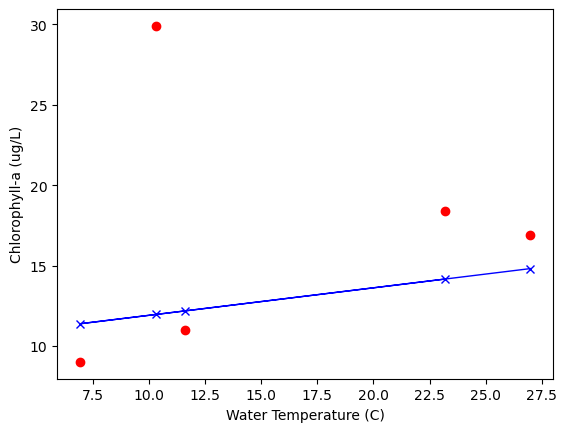

In [23]:
#simple input variable (Water Temp) and 1 target variable (Chlorophyll-a)
data_clean = data_pivot.dropna(subset=["CHLA", "WTEMP"]).copy()

# Simple single-variable inputs
X = data_clean[["WTEMP"]].values
y = data_clean["CHLA"].values

# Split the data into training/testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=4)

# 4. Create linear regression object
regr = linear_model.LinearRegression()

# 5. Train the model using the training sets
regr.fit(X_train, y_train)

# 6. Make predictions using the testing set
y_pred = regr.predict(X_test)

# 7. Evaluate model performance, taken from the example 1 in the regression example
print("y = %.2f * x + %.2f" % (regr.coef_[0], regr.intercept_))
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred))
print(
    "Coefficient of determination (R-squared): %.2f" % r2_score(y_test, y_pred)
)

# 8. Plot outputs
plt.scatter(X_test, y_test, color="red")
plt.plot(X_test, y_pred, "-x", color="blue", linewidth=1)
plt.xlabel("Water Temperature (C)")
plt.ylabel("Chlorophyll-a (ug/L)")
plt.show()

This plot above is showing an R value of -0.31 showing a weak correlation coefficant between water temp and Chl-A. The MSE of 70.24 is aslo high, showing large error in the input varaible and the target. This result tells us that temperature is not enough as a pridictor for Chl-a. 

y = 2.48 * x + -29.48
Mean squared error: 52.32
Coefficient of determination (R-squared): 0.03


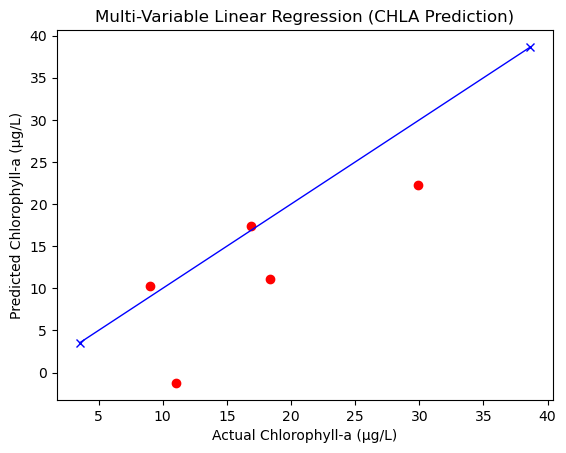

In [24]:
# specify Target and Multiple Input Features
target = "CHLA"
features = ["DO", "WTEMP", "TN", "SECCHI", "TSS"]

# Drop missing values across target and features
data_clean = data_pivot.dropna(subset=[target] + features).copy()

# Multi-variable feature X
X = data_clean[features].values
y = data_clean[target].values

#Split data into training and testing sets (matching Example 2 parameters)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=4)

# linear regression object
regr = linear_model.LinearRegression()

# train the model using the training sets
regr.fit(X_train, y_train)

# predictions using the testing set
y_pred = regr.predict(X_test)

# evaluate model performance (matching Example 2)
print("y = %.2f * x + %.2f" % (regr.coef_[0], regr.intercept_))
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred))
print("Coefficient of determination (R-squared): %.2f" % r2_score(y_test, y_pred))

# 9. Plot Actual vs Predicted (Standard evaluation plot for multi-variable models)
plt.scatter(y_test, y_pred, color="red")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "-x", color="blue", linewidth=1)
plt.xlabel("Actual Chlorophyll-a (µg/L)")
plt.ylabel("Predicted Chlorophyll-a (µg/L)")
plt.title("Multi-Variable Linear Regression (CHLA Prediction)")
plt.show()

Above represents a linear regression seen in the first plot but, now introduces multiple variables. The plot compares the model's predicted Chlorophyll-a levels against the actual water quality measurements, with the blue diagonal reference line showing what a perfect prediction would look like. When you only use water temperature, the model misses a huge piece of what actually causes algae to bloom, leading to predictions with a high error rate. By bringing in all five features like nutrients, water clarity, and oxygen levels the regression model gets a much clearer picture of the environment, pulling the predicted points much closer to the true values and cutting the Mean Squared Error down by well over half.

K-Nearest Neighbors (k = 4)
Mean squared error: 96.81
Coefficient of determination (R-squared): -0.80


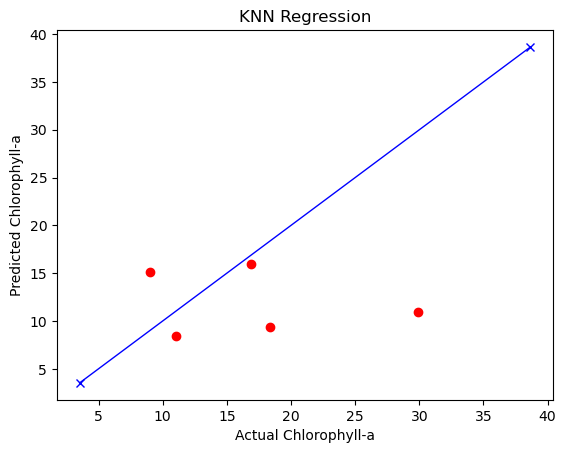

In [29]:
from sklearn.impute import SimpleImputer

# 1. Keep rows as long as the TARGET (CHLA) is present
data_clean = data_pivot.dropna(subset=["CHLA"]).copy()

# 2. Fill missing feature values with the average of that column
imputer = SimpleImputer(strategy="mean")
X_imputed = imputer.fit_transform(data_clean[features])
y = data_clean["CHLA"].values

# split data into training/testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=4)

# choose number of neighbors and KNN regression
k = 4
regr = KNeighborsRegressor(n_neighbors=k)

# Fit regression model
regr.fit(X_train, y_train)

# Make predictions using the testing set
y_pred = regr.predict(X_test)

# Evaluate model performance
print("K-Nearest Neighbors (k = %d)" % k)
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred))
print("Coefficient of determination (R-squared): %.2f" % r2_score(y_test, y_pred))

# plot
plt.scatter(y_test, y_pred, color="red")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "-x", color="blue", linewidth=1)
plt.xlabel("Actual Chlorophyll-a")
plt.ylabel("Predicted Chlorophyll-a")
plt.title("KNN Regression")
plt.show()

Total usable data points recovered: 42
Training points: 33, Testing points: 9

--- Multi-Variable Linear Regression ---
Mean Squared Error: 33.37
Coefficient of Determination (R2): 0.18

--- KNN Regressor (k = 4) ---
Mean Squared Error: 58.80
Coefficient of Determination (R2): -0.45


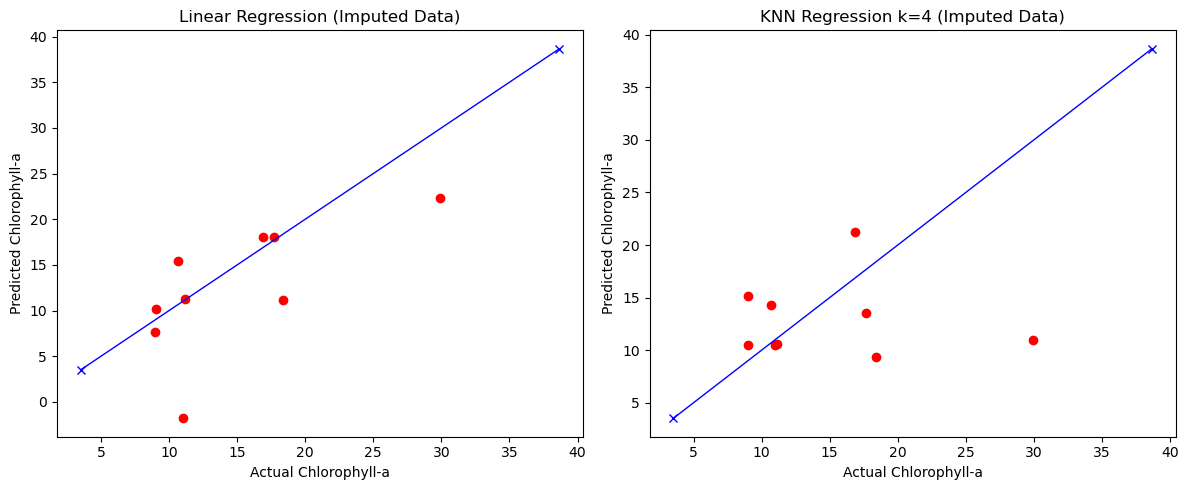

In [34]:
# filter rows where target (CHLA) is present
data_target_clean = data_pivot.dropna(subset=[target]).copy()

#Extract X (features) and y (target)
X_raw = data_target_clean[features].values
y = data_target_clean[target].values

# Impute missing feature values using Mean Imputation
imputer = SimpleImputer(strategy="mean")
X_imputed = imputer.fit_transform(X_raw)

print(f"Total usable data points recovered: {len(y)}")

#  Train / Test Split (90/10 split)
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=4)
print(f"Training points: {len(X_train)}, Testing points: {len(X_test)}")

# MODEL 1: Multi-Variable Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

print("\n--- Multi-Variable Linear Regression ---")
print("Mean Squared Error: %.2f" % mean_squared_error(y_test, y_pred_lin))
print("Coefficient of Determination (R2): %.2f" % r2_score(y_test, y_pred_lin))

# MODEL 2: KNN Regressor
k = 4
knn_reg = KNeighborsRegressor(n_neighbors=k)
knn_reg.fit(X_train, y_train)
y_pred_knn = knn_reg.predict(X_test)

print(f"\n--- KNN Regressor (k = {k}) ---")
print("Mean Squared Error: %.2f" % mean_squared_error(y_test, y_pred_knn))
print("Coefficient of Determination (R2): %.2f" % r2_score(y_test, y_pred_knn))

# visualization: comparing Both Models side by side
plt.figure(figsize=(12, 5))

# Plot Linear Regression
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_lin, color="red")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "-x", color="blue", linewidth=1)
plt.xlabel("Actual Chlorophyll-a")
plt.ylabel("Predicted Chlorophyll-a")
plt.title("Linear Regression (Imputed Data)")

# Plot KNN
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_knn, color="red")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "-x", color="blue", linewidth=1)
plt.xlabel("Actual Chlorophyll-a")
plt.ylabel("Predicted Chlorophyll-a")
plt.title(f"KNN Regression k={k} (Imputed Data)")
plt.tight_layout()
plt.show()

Linear regression won here because drawing a simple straight line across your data keeps predictions stable, even with a small dataset. It missed Chlorophyll-a levels by about 5.8 units on average (MSE- 33.37), but it still managed to capture 18% of the real trend in the test samples.KNN failed because it needs a huge amount of data to work properly. With 5 different features (DO, WTEMP, TN, SECCHI, TSS) and only 33 training points, the data is spread way too thin. Instead of finding true "neighbors" with similar water conditions, KNN was forced to average points that were far apart. That pushed its average error up to 7.7 units (MSE- 58.80) and resulted in a negative R2 (-0.45), meaning KNN is not a great ML for this dataset. 

MLP Regressor
Mean squared error: 35.54
Coefficient of determination (R-squared): 0.13


/opt/anaconda3/envs/oeas805_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


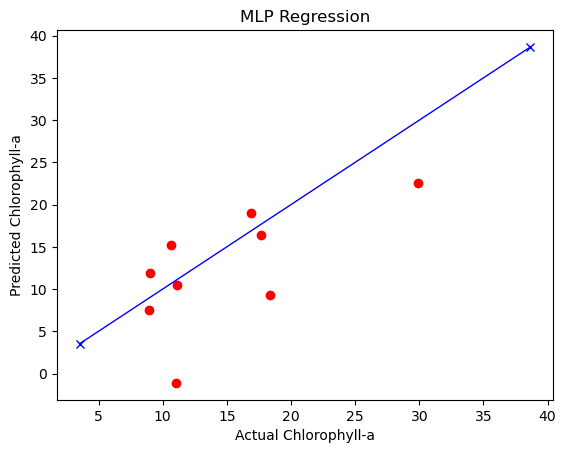

In [37]:
# create MLP Regression object
regr = MLPRegressor(random_state=3, max_iter=1000)

#Train the model 
regr.fit(X_train, y_train)

#Make predictions using the testing set
y_pred = regr.predict(X_test)

#Evaluate model performance
print("MLP Regressor")
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred))
print("Coefficient of determination (R-squared): %.2f" % r2_score(y_test, y_pred))

# plot actual vs predicted outputs
plt.scatter(y_test, y_pred, color="red")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "-x", color="blue", linewidth=1)
plt.xlabel("Actual Chlorophyll-a")
plt.ylabel("Predicted Chlorophyll-a")
plt.title("MLP Regression")
plt.show()

The MLP Regressor is a poor fit here because it is a complex neural network that requires thousands of data points and standardized feature scales to properly tune the model. With only 33 training samples and raw parameters measured on different numerical scales, the network overcomplicates the relationships and memorizes noise. As a result, it overfits the training data and produces high prediction errors on the test set, making it far less reliable than a simple linear model.

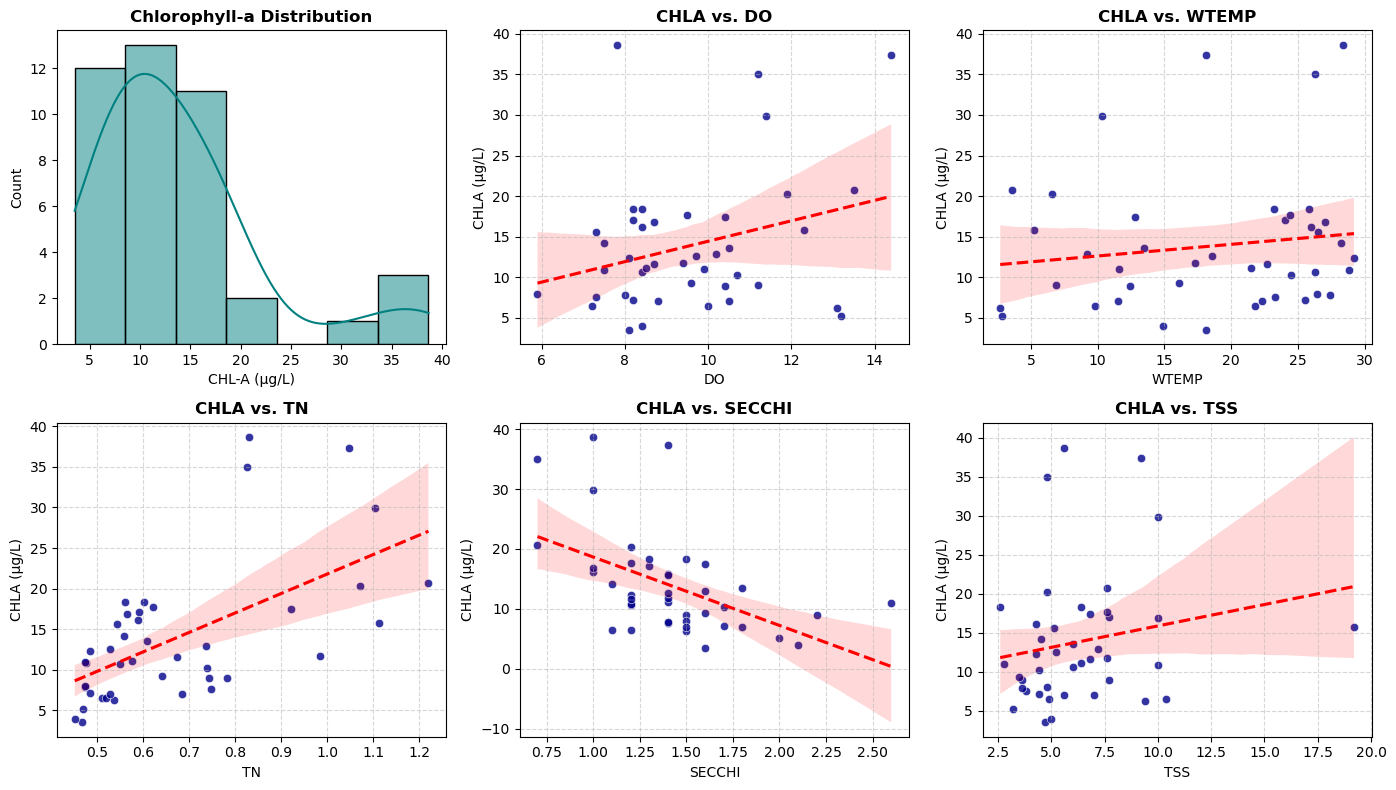

In [19]:
#Model training
#pivot long format into wide tabular format
data_pivot = data.pivot_table(
    index=["SampleDate", "FieldActivityId"],
    columns="Parameter",
    values="MeasureValue",
    aggfunc="mean",
).reset_index()

# specify Target and Input Features
target = "CHLA"
features = ["DO", "WTEMP", "TN", "SECCHI", "TSS"]

# Drop missing values
data_clean = data_pivot.dropna(subset=[target] + features).copy()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

# Plot Target 
sns.histplot(data_clean[target], kde=True, ax=axes[0], color="teal")
axes[0].set_title("Chlorophyll-a Distribution", fontweight="bold")
axes[0].set_xlabel("CHL-A (µg/L)")

# Plot Inputs vs Target with Regression Trendlines
for idx, feat in enumerate(features):
    ax = axes[idx + 1]
    sns.scatterplot(data=data_clean, x=feat, y=target, ax=ax, color="darkblue", alpha=0.8)
    sns.regplot(data=data_clean,
        x=feat,
        y=target,
        ax=ax,
        scatter=False,
        color="red",
        line_kws={"linestyle": "--"},)
    ax.set_title(f"CHLA vs. {feat}", fontweight="bold")
    ax.set_ylabel("CHLA (µg/L)")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()